# Actividad 3.1.2 · Implementación técnica del proyecto
**SCY1102 Gestión de Proyectos de Datos · Caso 3: Retail – Segmentación de clientes de un centro comercial**
Equipo: Cristian Romero, Javier Sagredo, Nicolas Osses, Rolando Paredes

Este cuadernillo implementa la fase técnica del plan (CRISP-DM: Datos → Preparación → Modelado → Evaluación → Despliegue).

**Cómo adaptamos la guía a nuestro caso.** La guía habla de variable dependiente y de predicciones, pero nuestro modelo es **no supervisado** (K-Means): no existe una variable que predecir, el modelo descubre grupos. Por eso:

| Paso de la guía | Cómo lo hacemos en nuestro caso |
|---|---|
| Variables dependiente e independientes | No hay variable dependiente. Variables del modelo: ingreso anual y puntaje de gasto. Género, edad, educación y estado civil **no entran al modelo**; se usan solo para auditar sesgos. |
| Train / test | Se ajusta el modelo con el 80% y se comprueba que los grupos se sostienen en el 20% que no vio. |
| Métricas | Silhouette (umbral del plan ≥ 0,5), Davies-Bouldin, Calinski-Harabasz y estabilidad (ARI). |
| 5 predicciones | Se asigna un segmento a 5 clientes nuevos. |
| Automatización | Script de reejecución mensual con alertas ligadas a los criterios del plan (silhouette y auditoría demográfica). |

## 1. Cargar el dataset del proyecto

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
SEED = 42   # misma semilla del informe, para que los segmentos coincidan

In [2]:
RUTA = 'Caso semestral_dataset.xlsx'
if not os.path.exists(RUTA):                      # en Colab: sube el archivo del caso
    from google.colab import files
    subido = files.upload()
    RUTA = list(subido.keys())[0]

df = pd.read_excel(RUTA)
df.columns = df.columns.str.strip()               # 'Education ' trae un espacio al final
df = df.rename(columns={'Annual Income (k$)': 'Ingreso', 'Spending Score (1-100)': 'Gasto'})
print(df.shape)
df.head()

(200, 7)


,CustomerID,Gender,Age,Education,Marital Status,Ingreso,Gasto
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


## 2. Analizar las clases y generar gráficos representativos
Primero la calidad de los datos (RD2: "Unknown" es dato faltante, no una categoría real) y luego las distribuciones.

In [3]:
print('Valores nulos por columna:'); print(df.isna().sum().to_string())
print('\nDuplicados:', df.duplicated().sum(), '| IDs repetidos:', df.CustomerID.duplicated().sum())
print('\nValores "Unknown" (faltantes encubiertos):')
for c in ['Education', 'Marital Status']:
    n = (df[c] == 'Unknown').sum()
    print(f'  {c}: {n} de {len(df)} = {n/len(df):.1%}')
df.describe().round(1)

Valores nulos por columna:
CustomerID        0
Gender            0
Age               0
Education         0
Marital Status    0
Ingreso           0
Gasto             0

Duplicados: 0 | IDs repetidos: 0

Valores "Unknown" (faltantes encubiertos):
  Education: 26 de 200 = 13.0%
  Marital Status: 15 de 200 = 7.5%


,CustomerID,Age,Ingreso,Gasto
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


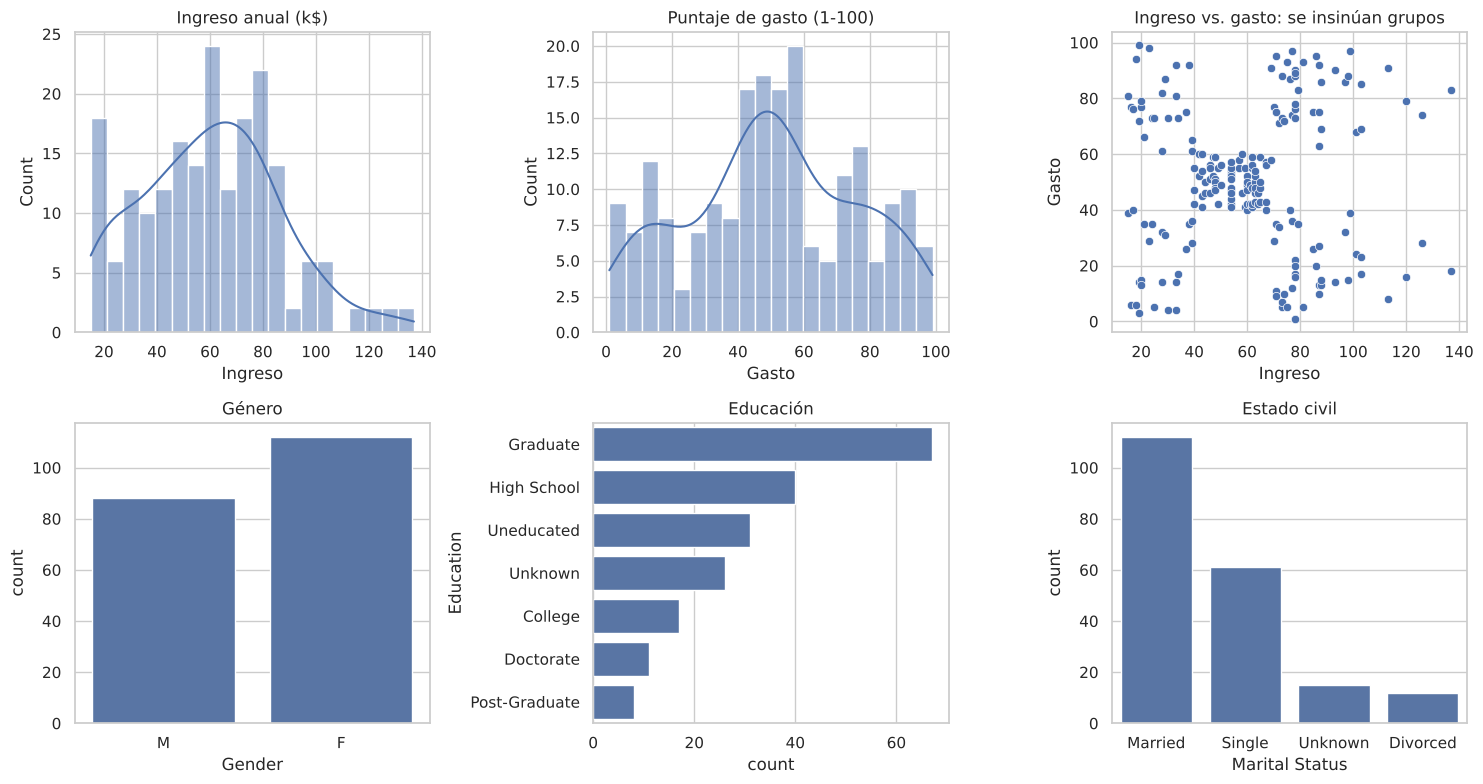

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df.Ingreso, bins=20, kde=True, ax=ax[0,0]).set(title='Ingreso anual (k$)')
sns.histplot(df.Gasto, bins=20, kde=True, ax=ax[0,1]).set(title='Puntaje de gasto (1-100)')
sns.scatterplot(data=df, x='Ingreso', y='Gasto', ax=ax[0,2]).set(title='Ingreso vs. gasto: se insinúan grupos')
sns.countplot(data=df, x='Gender', ax=ax[1,0]).set(title='Género')
sns.countplot(data=df, y='Education', order=df.Education.value_counts().index, ax=ax[1,1]).set(title='Educación')
sns.countplot(data=df, x='Marital Status', order=df['Marital Status'].value_counts().index, ax=ax[1,2]).set(title='Estado civil')
plt.tight_layout(); plt.show()

Ingreso: límites [-13.2, 132.8] -> 2 atípicos [137, 137]
Gasto: límites [-22.6, 130.4] -> 0 atípicos []


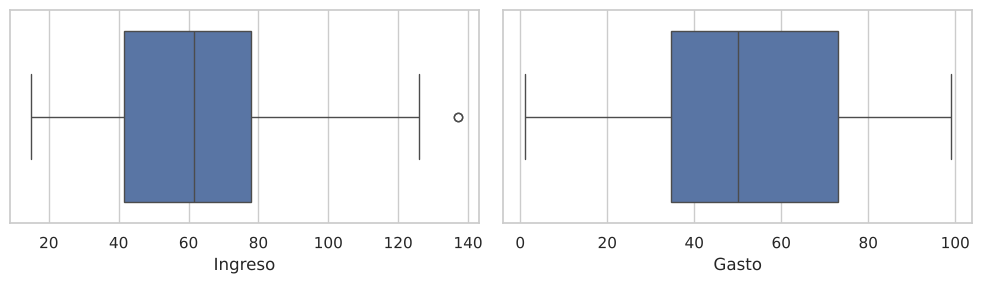

In [5]:
# Valores atípicos con el método IQR (RD5): se detectan, se documentan y se conservan si son clientes reales
for c in ['Ingreso', 'Gasto']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    fuera = df[(df[c] < lo) | (df[c] > hi)]
    print(f'{c}: límites [{lo:.1f}, {hi:.1f}] -> {len(fuera)} atípicos', fuera[c].tolist())
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=df.Ingreso, ax=ax[0]); sns.boxplot(x=df.Gasto, ax=ax[1]); plt.tight_layout(); plt.show()

**Lectura.** Los datos están completos salvo los "Unknown" (13% en educación y 7,5% en estado civil). Ingreso y gasto no son normales y en el gráfico de dispersión ya se ven zonas densas, lo que sugiere grupos. Hay 2 atípicos de ingreso; son clientes reales, así que se conservan y se documentan.

## 3. Preparar los datos y seleccionar variables
- **"Unknown" → dato faltante** (RD2).
- **Anonimización (RL):** `CustomerID` se reemplaza por un hash con sal; el identificador original no sale del cuadernillo.
- **Variables del modelo (X):** `Ingreso` y `Gasto`. **No hay variable dependiente (y)** porque el modelo es no supervisado.
- **Variables sensibles** (género, edad, educación, estado civil) quedan fuera del modelo y se guardan aparte solo para la **auditoría demográfica**. Hashearlas y usarlas no las anonimiza ni evita el sesgo, porque el modelo seguiría usando esa información.

In [6]:
import hashlib
SAL = 'cambiar-esta-sal-en-produccion'
def anonimizar(i): return hashlib.sha256(f'{SAL}-{i}'.encode()).hexdigest()[:10]

dfp = df.copy()
dfp[['Education', 'Marital Status']] = dfp[['Education', 'Marital Status']].replace('Unknown', np.nan)
dfp['cliente'] = dfp.CustomerID.map(anonimizar)
dfp = dfp.drop(columns='CustomerID')

VARS_MODELO = ['Ingreso', 'Gasto']                                   # X
VARS_AUDITORIA = ['Gender', 'Age', 'Education', 'Marital Status']    # solo para auditar
X = dfp[VARS_MODELO]
print('Variables del modelo:', VARS_MODELO)
print('Variables solo para auditoría:', VARS_AUDITORIA)
dfp.head()

Variables del modelo: ['Ingreso', 'Gasto']
Variables solo para auditoría: ['Gender', 'Age', 'Education', 'Marital Status']


,Gender,Age,Education,Marital Status,Ingreso,Gasto,cliente
0,M,19,High School,Married,15,39,0a6ac37004
1,M,21,Graduate,Single,15,81,90156c9072
2,F,20,Graduate,Married,16,6,8673911755
3,F,23,High School,NaN,16,77,f44476d3b4
4,F,31,Uneducated,Married,17,40,228c44d50c


## 4. Separar los datos en entrenamiento y test
80% para entrenar y 20% para comprobar que los grupos se sostienen en clientes que el modelo no vio. El escalador se ajusta **solo con entrenamiento** para no filtrar información del test.

In [7]:
X_tr, X_te = train_test_split(X, test_size=0.20, random_state=SEED)
esc = StandardScaler().fit(X_tr)                 # estandarización (RD6): media 0, desviación 1
Z_tr, Z_te = esc.transform(X_tr), esc.transform(X_te)
print('Entrenamiento:', Z_tr.shape, '| Test:', Z_te.shape)
print('Media y desviación en entrenamiento (≈ 0 y 1):', Z_tr.mean(0).round(2), Z_tr.std(0).round(2))

Entrenamiento: (160, 2) | Test: (40, 2)
Media y desviación en entrenamiento (≈ 0 y 1): [-0.  0.] [1. 1.]


## 5. Entrenar el modelo
Primero se elige k (2 a 10) con el método del codo y el silhouette, usando solo el conjunto de entrenamiento.

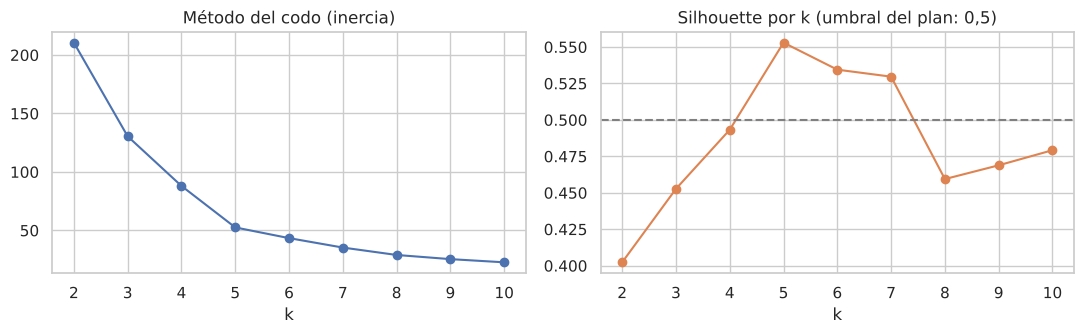

,0,1,2,3,4,5,6,7,8
k,2.000,3.000,4.000,5.000,6.000,7.00,8.000,9.000,10.000
inercia,210.600,130.500,88.000,52.500,43.400,35.30,29.000,25.400,22.700
silhouette,0.402,0.453,0.493,0.553,0.534,0.53,0.459,0.469,0.479


In [8]:
ks = range(2, 11); inercia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Z_tr)
    inercia.append(m.inertia_); sil.append(silhouette_score(Z_tr, m.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, inercia, 'o-'); ax[0].set(title='Método del codo (inercia)', xlabel='k')
ax[1].plot(ks, sil, 'o-', color='C1'); ax[1].axhline(0.5, ls='--', color='gray'); ax[1].set(title='Silhouette por k (umbral del plan: 0,5)', xlabel='k')
plt.tight_layout(); plt.show()
pd.DataFrame({'k': list(ks), 'inercia': np.round(inercia, 1), 'silhouette': np.round(sil, 3)}).T

In [9]:
K = 5   # decisión del plan: codo + silhouette + interpretabilidad para marketing
modelo = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(Z_tr)
print('Modelo entrenado con', len(Z_tr), 'clientes. Iteraciones:', modelo.n_iter_)

Modelo entrenado con 160 clientes. Iteraciones: 6


**¿Fueron suficientes los pasos anteriores?** Se revisa con tres señales, en la sección siguiente: (1) silhouette sobre el umbral del plan, (2) que el resultado se mantenga en el conjunto test y (3) que los segmentos tengan tamaños razonables y un perfil que marketing pueda entender.

## 6. Evaluar con métricas de desempeño

In [10]:
def metricas(Z, etiquetas):
    return {'silhouette': silhouette_score(Z, etiquetas),
            'davies_bouldin': davies_bouldin_score(Z, etiquetas),
            'calinski_harabasz': calinski_harabasz_score(Z, etiquetas)}

lab_tr = modelo.labels_
lab_te = modelo.predict(Z_te)
res = pd.DataFrame({'entrenamiento': metricas(Z_tr, lab_tr), 'test': metricas(Z_te, lab_te)}).round(3)
display(res)

# Estabilidad: ¿los segmentos del modelo de entrenamiento coinciden con los de un modelo ajustado con todos los clientes?
esc_all = StandardScaler().fit(X); Z_all = esc_all.transform(X)
final = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(Z_all)      # modelo final = el del informe
ari = adjusted_rand_score(final.predict(esc_all.transform(X_te)), lab_te)
print(f'Estabilidad (ARI entre modelo de entrenamiento y modelo final, sobre test): {ari:.2f}  (1 = idénticos)')
print(f'Silhouette del modelo final (200 clientes): {silhouette_score(Z_all, final.labels_):.3f}')

,entrenamiento,test
silhouette,0.553,0.567
davies_bouldin,0.577,0.525
calinski_harabasz,197.224,58.346


Estabilidad (ARI entre modelo de entrenamiento y modelo final, sobre test): 1.00  (1 = idénticos)
Silhouette del modelo final (200 clientes): 0.555


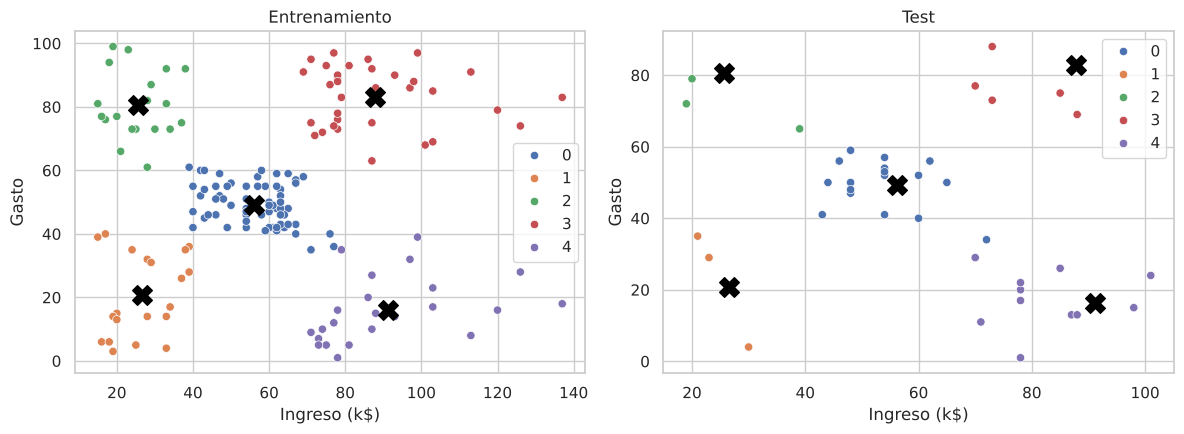

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (Z, lab, t) in zip(ax, [(Z_tr, lab_tr, 'Entrenamiento'), (Z_te, lab_te, 'Test')]):
    sns.scatterplot(x=esc.inverse_transform(Z)[:,0], y=esc.inverse_transform(Z)[:,1], hue=lab, palette='deep', ax=a)
    c = esc.inverse_transform(modelo.cluster_centers_)
    a.scatter(c[:,0], c[:,1], marker='X', s=200, c='black'); a.set(title=t, xlabel='Ingreso (k$)', ylabel='Gasto')
plt.tight_layout(); plt.show()

### Modelo final y perfil de los segmentos
Para el uso real se ajusta con los 200 clientes (con la misma semilla del informe, así los segmentos 0 a 4 coinciden con los del documento).

,clientes,edad_media,Ingreso,Gasto,perfil
segmento,,,,,
0,81,42.7,55.3,49.5,"ingreso medio, gasto medio"
1,39,32.7,86.5,82.1,"ingreso alto, gasto alto"
2,22,25.3,25.7,79.4,"ingreso bajo, gasto alto"
3,35,41.1,88.2,17.1,"ingreso alto, gasto bajo"
4,23,45.2,26.3,20.9,"ingreso bajo, gasto bajo"


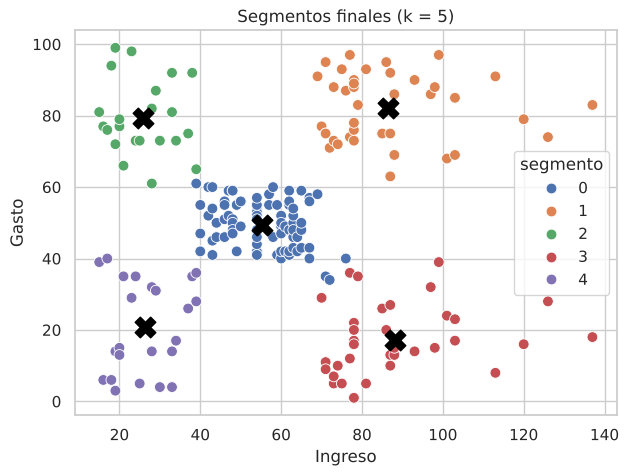

In [12]:
def nivel(v, bajo, alto): return 'bajo' if v < bajo else 'alto' if v > alto else 'medio'
dfp['segmento'] = final.labels_
cent = pd.DataFrame(esc_all.inverse_transform(final.cluster_centers_), columns=['Ingreso', 'Gasto'])
perfil = dfp.groupby('segmento').agg(clientes=('segmento', 'size'), edad_media=('Age', 'mean')).join(cent.round(1))
perfil['perfil'] = ['ingreso ' + nivel(r.Ingreso, 40, 70) + ', gasto ' + nivel(r.Gasto, 35, 65) for r in perfil.itertuples()]
perfil['edad_media'] = perfil.edad_media.round(1)
display(perfil)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=dfp, x='Ingreso', y='Gasto', hue='segmento', palette='deep', s=60)
plt.scatter(cent.Ingreso, cent.Gasto, marker='X', s=220, c='black'); plt.title('Segmentos finales (k = 5)'); plt.show()

### Auditoría demográfica (riesgo crítico R1)
Se compara la composición de cada segmento con la del total. Si la diferencia supera **10 puntos porcentuales**, se avisa a Legal (RL6). Las variables sensibles no entran al modelo, pero los segmentos igual pueden concentrarlas.

In [13]:
UMBRAL_PP = 10
def auditoria(d, segmentos='segmento', variables=('Gender', 'Education', 'Marital Status'), umbral=UMBRAL_PP):
    filas = []
    for v in variables:
        col = d[v].fillna('Unknown')                      # en la auditoría se muestra "Unknown" como categoría
        total = col.value_counts(normalize=True) * 100
        por_seg = pd.crosstab(d[segmentos], col, normalize='index') * 100
        for s in por_seg.index:
            for cat in por_seg.columns:
                dif = por_seg.loc[s, cat] - total[cat]
                filas.append((s, v, cat, round(por_seg.loc[s, cat], 1), round(total[cat], 1), round(dif, 1), abs(dif) > umbral))
    return pd.DataFrame(filas, columns=['segmento', 'variable', 'categoría', '% segmento', '% total', 'diferencia (pp)', 'alerta'])

aud = auditoria(dfp)
alertas = aud[aud.alerta].sort_values('diferencia (pp)', ascending=False)
display(alertas)

,segmento,variable,categoría,% segmento,% total,diferencia (pp),alerta
30,2,Education,Unknown,27.3,13.0,14.3,True
56,2,Marital Status,Unknown,18.2,7.5,10.7,True
7,3,Gender,M,54.3,44.0,10.3,True
36,3,Education,Uneducated,25.7,15.5,10.2,True
37,3,Education,Unknown,2.9,13.0,-10.1,True
6,3,Gender,F,45.7,56.0,-10.3,True
33,3,Education,Graduate,22.9,33.5,-10.6,True


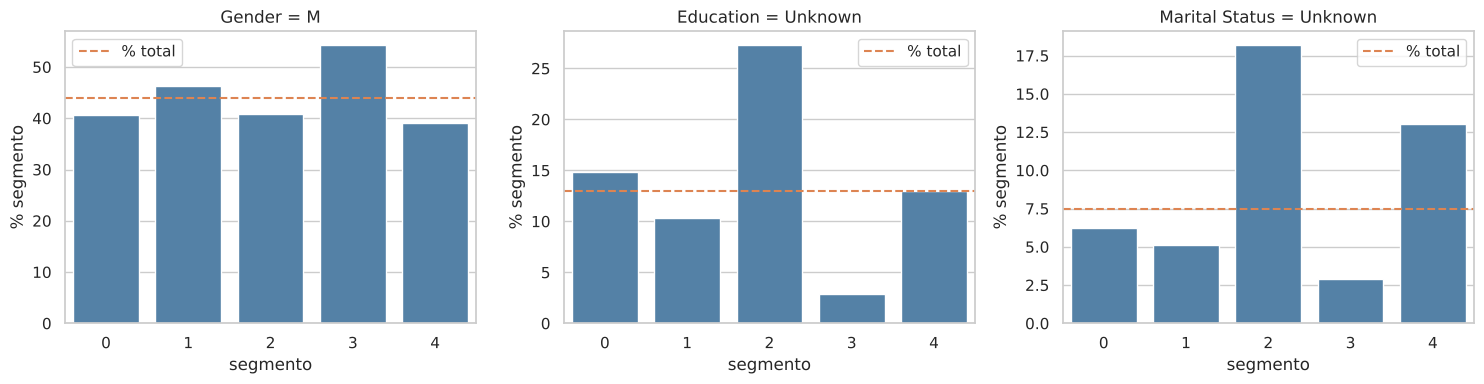

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (v, cat) in zip(ax, [('Gender', 'M'), ('Education', 'Unknown'), ('Marital Status', 'Unknown')]):
    t = aud[(aud.variable == v) & (aud['categoría'] == cat)]
    sns.barplot(data=t, x='segmento', y='% segmento', ax=a, color='steelblue')
    a.axhline(t['% total'].iloc[0], color='C1', ls='--', label='% total'); a.set(title=f'{v} = {cat}'); a.legend()
plt.tight_layout(); plt.show()

**Lectura.** En los números el modelo es sólido, pero la auditoría detecta lo que el plan ya anticipaba: el segmento 3 concentra hombres (54,3% frente a 44% del total) y el segmento 2 concentra educación y estado civil desconocidos. El modelo no usa esas variables; el riesgo está en **cómo se usan los segmentos**. Con 22 y 35 clientes, los segmentos 2 y 3 son pequeños, así que sus porcentajes se mueven mucho; por eso la auditoría también marca diferencias de educación en el segmento 3 ("Uneducated" y "Graduate" a ±10 puntos, justo en el umbral). Son señales para que Legal las mire, no conclusiones definitivas. Por eso el plan exige revisión humana de cada campaña y un aviso de uso responsable en el dashboard.

## 7. Usar el modelo con nuevos datos: 5 predicciones

,Ingreso,Gasto,segmento,perfil del segmento
cliente_A,20,85,2,"ingreso bajo, gasto alto"
cliente_B,95,15,3,"ingreso alto, gasto bajo"
cliente_C,60,50,0,"ingreso medio, gasto medio"
cliente_D,110,90,1,"ingreso alto, gasto alto"
cliente_E,28,12,4,"ingreso bajo, gasto bajo"


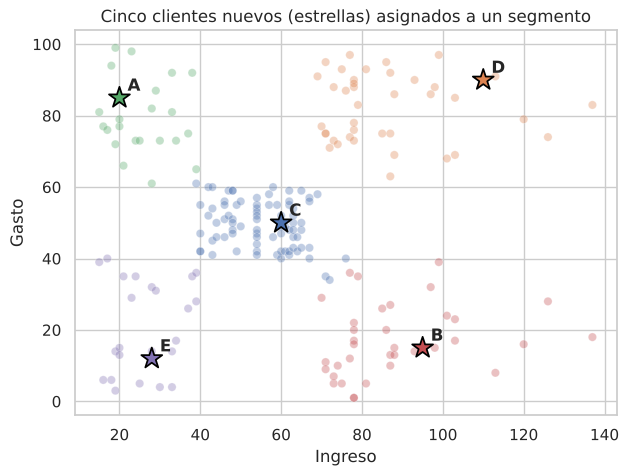

In [15]:
nuevos = pd.DataFrame({'Ingreso': [20, 95, 60, 110, 28], 'Gasto': [85, 15, 50, 90, 12]},
                      index=['cliente_A', 'cliente_B', 'cliente_C', 'cliente_D', 'cliente_E'])
nuevos['segmento'] = final.predict(esc_all.transform(nuevos))
nuevos['perfil del segmento'] = nuevos.segmento.map(perfil.perfil)
display(nuevos)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=dfp, x='Ingreso', y='Gasto', hue='segmento', palette='deep', alpha=.35, legend=False)
sns.scatterplot(data=nuevos, x='Ingreso', y='Gasto', hue='segmento', palette='deep', s=250, marker='*', edgecolor='black', legend=False)
for n, r in nuevos.iterrows(): plt.annotate(n[-1], (r.Ingreso + 2, r.Gasto + 2), weight='bold')
plt.title('Cinco clientes nuevos (estrellas) asignados a un segmento'); plt.show()

Una predicción en clustering significa **asignar el cliente al centroide más cercano**. El modelo no "adivina" nada sobre la persona: solo la ubica según su ingreso y su gasto.

## 8. Proponer e implementar una automatización
El plan contempla **reejecución mensual** del modelo. Se automatiza como un script que, cada vez que llega un archivo nuevo de clientes:
1. valida y limpia los datos ("Unknown" → faltante, anonimiza el ID);
2. asigna segmentos con el modelo guardado;
3. ejecuta la auditoría demográfica;
4. calcula el silhouette y lo compara con el umbral del plan (0,5);
5. guarda los resultados y un reporte de estado, y **marca ALERTA** si falla algún control (así se cumple la revisión humana: la persona revisa antes de que se use una campaña).

Primero se guarda el modelo entrenado.

In [16]:
import joblib
joblib.dump({'escalador': esc_all, 'modelo': final, 'perfil': perfil['perfil'].to_dict(), 'k': K, 'semilla': SEED}, 'modelo_segmentacion.joblib')
print('Modelo guardado: modelo_segmentacion.joblib')

Modelo guardado: modelo_segmentacion.joblib


In [17]:
%%writefile segmentacion_mensual.py
"""Reejecución mensual de la segmentación de clientes (Caso 3 · SCY1102).
Uso:  python segmentacion_mensual.py clientes.xlsx [carpeta_salida]
Programación (ejemplo cron, día 1 de cada mes 07:00):  0 7 1 * *  python segmentacion_mensual.py clientes.xlsx salidas
"""
import sys, os, json, hashlib, datetime as dt
import numpy as np, pandas as pd, joblib
from sklearn.metrics import silhouette_score

UMBRAL_SILHOUETTE = 0.5     # criterio de salida de la fase Modelado
UMBRAL_PP = 10              # auditoría demográfica (RL6)
SAL = os.environ.get('SAL_ANONIMIZACION', 'cambiar-esta-sal-en-produccion')

def limpiar(df):
    df = df.copy(); df.columns = df.columns.str.strip()
    df = df.rename(columns={'Annual Income (k$)': 'Ingreso', 'Spending Score (1-100)': 'Gasto'})
    faltan = {'CustomerID', 'Ingreso', 'Gasto'} - set(df.columns)
    if faltan: raise ValueError(f'Faltan columnas obligatorias: {faltan}')
    for c in ('Education', 'Marital Status'):
        if c in df: df[c] = df[c].replace('Unknown', np.nan)
    df['cliente'] = df.CustomerID.map(lambda i: hashlib.sha256(f'{SAL}-{i}'.encode()).hexdigest()[:10])
    return df.drop(columns='CustomerID')

def auditar(df, variables=('Gender', 'Education', 'Marital Status')):
    alertas = []
    for v in variables:
        if v not in df: continue
        col = df[v].fillna('Unknown'); total = col.value_counts(normalize=True) * 100
        por_seg = pd.crosstab(df['segmento'], col, normalize='index') * 100
        for s in por_seg.index:
            for cat in por_seg.columns:
                dif = por_seg.loc[s, cat] - total[cat]
                if abs(dif) > UMBRAL_PP:
                    alertas.append({'segmento': int(s), 'variable': v, 'categoria': cat, 'diferencia_pp': round(float(dif), 1)})
    return alertas

def ejecutar(ruta_entrada, carpeta_salida='salidas', ruta_modelo='modelo_segmentacion.joblib'):
    os.makedirs(carpeta_salida, exist_ok=True)
    art = joblib.load(ruta_modelo)
    df = limpiar(pd.read_excel(ruta_entrada) if ruta_entrada.endswith('xlsx') else pd.read_csv(ruta_entrada))
    Z = art['escalador'].transform(df[['Ingreso', 'Gasto']])
    df['segmento'] = art['modelo'].predict(Z)
    df['perfil'] = df.segmento.map(art['perfil'])
    sil = float(silhouette_score(Z, df.segmento))
    alertas = auditar(df)
    estado = 'OK' if sil >= UMBRAL_SILHOUETTE and not alertas else 'ALERTA: revisar antes de usar'
    marca = dt.date.today().isoformat()
    df.to_csv(os.path.join(carpeta_salida, f'segmentos_{marca}.csv'), index=False)
    reporte = {'fecha': marca, 'clientes': len(df), 'silhouette': round(sil, 3), 'umbral_silhouette': UMBRAL_SILHOUETTE,
               'tamano_segmentos': {int(k): int(v) for k, v in df.segmento.value_counts().sort_index().items()},
               'alertas_auditoria': alertas, 'estado': estado,
               'nota': 'Revisión humana obligatoria de cada campaña (RL5). No usar los segmentos para excluir ni discriminar.'}
    with open(os.path.join(carpeta_salida, f'reporte_{marca}.json'), 'w', encoding='utf-8') as f:
        json.dump(reporte, f, ensure_ascii=False, indent=2)
    return reporte

if __name__ == '__main__':
    r = ejecutar(sys.argv[1], sys.argv[2] if len(sys.argv) > 2 else 'salidas')
    print(json.dumps(r, ensure_ascii=False, indent=2))

Overwriting segmentacion_mensual.py


In [18]:
# Prueba de la automatización con el archivo del caso (en el mes real sería el archivo nuevo de clientes)
import sys; sys.path.insert(0, '.')
import importlib, segmentacion_mensual; importlib.reload(segmentacion_mensual)
reporte = segmentacion_mensual.ejecutar(RUTA, 'salidas')
import json; print(json.dumps({k: v for k, v in reporte.items() if k != 'alertas_auditoria'}, ensure_ascii=False, indent=2))
print('Alertas de auditoría:', len(reporte['alertas_auditoria']))
print(os.listdir('salidas'))

{
  "fecha": "2026-10-27",
  "clientes": 200,
  "silhouette": 0.555,
  "umbral_silhouette": 0.5,
  "tamano_segmentos": {
    "0": 81,
    "1": 39,
    "2": 22,
    "3": 35,
    "4": 23
  },
  "estado": "ALERTA: revisar antes de usar",
  "nota": "Revisión humana obligatoria de cada campaña (RL5). No usar los segmentos para excluir ni discriminar."
}
Alertas de auditoría: 7
['segmentos_2026-10-27.csv', 'reporte_2026-10-27.json']


**Qué automatiza y qué no.** Se automatiza lo repetitivo (limpieza, asignación, auditoría, reporte) y los **controles del plan**: si el silhouette baja de 0,5 o la auditoría detecta una diferencia mayor a 10 puntos, el estado queda en ALERTA y el equipo vuelve a la fase que corresponde (Preparación o Negocio). **No** se automatiza la decisión de usar los segmentos: esa sigue siendo humana.

**Gestión (Jira/Trello).** Sugerencia de tarjetas para el tablero, una por paso de este cuadernillo: *Cargar y validar dataset · EDA y gráficos · Preparación y anonimización · Split train/test · Elegir k y entrenar · Evaluación y auditoría · Predicciones de prueba · Automatización mensual*. Cada una con responsable según la RACI (Nicolas: datos; Javier: modelo y auditoría; Cristian: seguimiento; Rolando: perfiles y comunicación a marketing).

## Reflexión grupal
**¿Qué componente tendrá mayor impacto en el éxito del negocio: el modelo, la automatización o la forma de comunicar los resultados?**

**Nuestra respuesta: la forma de comunicar los resultados.**

- **El modelo ya cumple y rinde poco más.** Con silhouette 0,555 y segmentos interpretables, seguir afinándolo da retornos pequeños. Con solo dos variables y 200 clientes, el límite está en los datos, no en el algoritmo.
- **El valor aparece cuando marketing decide distinto.** Los segmentos no generan ingresos por sí solos; los generan las campañas, la ubicación de tiendas y la experiencia de compra que se cambian a partir de ellos. Marketing no es técnico: si no entiende "ingreso alto, gasto bajo" y qué hacer con ese grupo, el modelo no se usa. Por eso el dashboard, los perfiles en lenguaje simple y la capacitación son parte del alcance (E3).
- **Aquí también está el riesgo crítico.** La auditoría mostró que los segmentos concentran grupos (segmento 3: 54,3% hombres; segmento 2: más educación y estado civil desconocidos). El sesgo ocurre en el uso, y se evita comunicando bien: aviso de uso responsable, límites claros y revisión humana de cada campaña.
- **La automatización es la base, pero habilita en lugar de decidir.** Aporta consistencia y los controles de calidad, pero con 200 clientes y una ejecución mensual ahorra poco tiempo. Su mayor valor es que no se omita la auditoría.

**Matiz:** los tres se necesitan. Un modelo que falla invalida todo lo demás, y sin automatización los controles dependen de que alguien se acuerde. Pero, una vez que el modelo supera el umbral, el factor que más cambia el resultado del negocio es que las personas lo entiendan y lo usen bien.